
# BrightCart — E-commerce Profitability & Decision Intelligence

## Project overview

BrightCart is a Python-based business analytics portfolio project that investigates e-commerce transaction profitability, operational cost drivers, reported marketing performance, and management decision scenarios.

**Reporting period:** January 2024 – December 2025

### Business objectives

- Validate recorded revenue, transaction costs, and contribution profit.
- Identify the most and least profitable product categories and sales channels.
- Investigate return rates, refund exposure, shipping costs, and platform fees.
- Compare advertising platforms using reported attribution metrics.
- Model alternative marketing budget reductions.
- Quantify hypothetical operational improvement opportunities.
- Provide an interactive dashboard for exploring the findings.

### Datasets

The project uses three CSV datasets:

| Dataset | Contents | Analytical purpose |
|---|---|---|
| Orders | 2,000 original transactions; 1,997 in the shared reporting period | Financial reconciliation, contribution analysis, and returns |
| Products | 207 product records | Reference data and product catalog context |
| Marketing Spend | 144 platform-month records | Reported marketing performance and budget scenarios |

### Methodology and limitations

Order-level calculations use validated financial equations and reusable Python modules with automated tests.

**Profitability refers to pre-marketing transaction contribution, not company net income.**

The Products dataset cannot be joined reliably to individual Orders using the available fields.

Marketing-attributed revenue is not reconcilable to the recorded Orders revenue. Consequently, reported ROAS is analyzed separately and is not interpreted as verified incremental profitability.

Scenario savings are hypothetical, not realized results.


## 1. Load and validate the datasets

The project uses three CSV files: Orders, Products,
and Marketing Spend.

The reusable data loader validates input schemas,
identifiers, and reporting dates.

In [8]:

import pandas as pd

# Confirm the dependency is available before continuing
# with our reusable BrightCart analysis modules
print("BRIGHTCART — DEPENDENCY VERIFICATION")
print("=" * 55)

print("Pandas version:", pd.__version__)
print("Pandas import: PASS")




BRIGHTCART — DEPENDENCY VERIFICATION
Pandas version: 3.0.2
Pandas import: PASS


In [3]:
from pathlib import Path
import sys
import importlib

# Locate BrightCart using project files rather than
# relying on an environment-specific absolute path
candidate_directories = [
    Path.cwd(),
    Path.cwd() / "Bright cart",
    Path.cwd().parent,
    Path.cwd().parent / "Bright cart",
]

project_root = next(
    (
        directory
        for directory in candidate_directories
        if (directory / "orders.csv").is_file()
        and (directory / "brightcart" / "data_loader.py").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "BrightCart project not found. "
        "Start Jupyter in the project folder or its parent."
    )

# Make the reusable package importable even when
# the notebook kernel starts from the parent directory
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

importlib.invalidate_caches()

from brightcart.data_loader import load_brightcart_data
from brightcart.financials import validate_order_financials

# Load the validated datasets for the shared period
data = load_brightcart_data(
    data_dir=project_root,
    start_month="2024-01",
    end_month="2025-12"
)

orders = data["financial_orders"]

print("Reporting-period orders:", len(orders))
print("Products:", len(data["products"]))
print("Marketing records:", len(data["financial_marketing"]))


Reporting-period orders: 1997
Products: 207
Marketing records: 144


## 2. Financial reconciliation

Before analyzing profitability, validate that every
original order satisfies the recorded revenue,
cost, and contribution profit equations.

In [10]:
# Audit all source orders, including transactions
# outside the shared marketing reporting window
audit = validate_order_financials(data["orders"])

# Reject inconsistent accounting data
# before displaying financial conclusions
assert audit["all_valid"], audit

# Calculate the verified financial baseline
# from the 1,997 reporting-period order records
net_revenue = orders["net_revenue"].sum()
contribution = orders["profit"].sum()

# Calculate the revenue-weighted contribution margin
# rather than averaging individual order margins
contribution_margin = (
    contribution / net_revenue * 100
    if net_revenue != 0
    else float("nan")
)

print("Orders audited:", audit["orders_checked"])
print(f"Net revenue: ${net_revenue:,.2f}")
print(f"Pre-marketing contribution: ${contribution:,.2f}")
print(f"Contribution margin: {contribution_margin:.2f}%")
print("Financial reconciliation: PASS")

Orders audited: 2000
Net revenue: $236,015.05
Pre-marketing contribution: $56,219.55
Contribution margin: 23.82%
Financial reconciliation: PASS


In [11]:

# BRIGHTCART — FINAL NOTEBOOK REPRODUCIBILITY TEST

# Verify that the reusable data loader produced
# the expected number of transactions
assert len(data["orders"]) == 2000
assert len(orders) == 1997
assert len(data["products"]) == 207

# Verify that the marketing records cover
# the expected 24-month reporting period
assert len(data["financial_marketing"]) == 144

# Compare financial amounts in cents
# to avoid floating-point equality problems
assert round(net_revenue * 100) == 23601505
assert round(contribution * 100) == 5621955

# Verify the overall contribution margin
# against our previously reconciled baseline
assert round(contribution_margin, 2) == 23.82

# Confirm that all source financial equations passed
assert audit["all_valid"]

print("BRIGHTCART — FINAL NOTEBOOK VERIFICATION")
print("=" * 55)

print("Data loading: PASS")
print("Reporting period: PASS")
print("Financial reconciliation: PASS")
print("Profit calculations: PASS")

print("\nFinal notebook financial baseline validated!")


BRIGHTCART — FINAL NOTEBOOK VERIFICATION
Data loading: PASS
Reporting period: PASS
Financial reconciliation: PASS
Profit calculations: PASS

Final notebook financial baseline validated!



## 3. Category and Sales Channel Profitability

### Business questions

- Which categories generate the highest contribution profit?
- Which sales channels retain the highest share of net revenue?
- How do shipping costs and marketplace fees affect margins?

**Financial definitions**

- Net revenue = gross revenue − discounts − refunds.
- Pre-marketing contribution profit = net revenue − recorded transaction costs.
- Contribution margin = contribution profit ÷ net revenue × 100.

All results in this section use the validated January 2024–December 2025 Orders data.

Marketing expenditure is excluded from these contribution calculations because the marketing attribution dataset does not reconcile with recorded order revenue.


In [13]:

import pandas as pd
from IPython.display import display

# Group the validated reporting-period orders by category
# to calculate financial performance for each product category
category_summary = (
    orders
    .groupby("primary_category", as_index=False)
    .agg(
        # Count orders to measure transaction volume
        order_count=("order_id", "nunique"),

        # Sum recorded net revenue after discounts and refunds
        net_revenue=("net_revenue", "sum"),

        # Sum the recorded pre-marketing contribution profit
        contribution_profit=("profit", "sum"),

        # Calculate the historical shipping cost base
        shipping_cost=("shipping_cost", "sum"),

        # Calculate the refunded amount for each category
        refunds=("refund_amount", "sum")
    )
)

# Calculate margins from aggregated revenue and profit
# rather than averaging individual transaction margins
category_summary["margin_pct"] = (
    category_summary["contribution_profit"]
    / category_summary["net_revenue"]
    * 100
)

# Sort by contribution profit in descending order
# so the highest-contributing category appears first
category_summary = category_summary.sort_values(
    "contribution_profit",
    ascending=False
).reset_index(drop=True)

# Verify all category totals reconcile to the baseline
# so no category was lost during grouping
assert category_summary["order_count"].sum() == len(orders)

assert round(
    category_summary["net_revenue"].sum() * 100
) == 23601505

assert round(
    category_summary["contribution_profit"].sum() * 100
) == 5621955

# Display a formatted report while preserving numeric data
# for further calculations and visualizations
print("BRIGHTCART — CATEGORY PROFITABILITY")
print("=" * 55)

from IPython.display import display

# Create a separate presentation copy of the summary
# so dollar symbols never replace the numeric values
# needed for financial calculations and future charts
category_display = category_summary.copy()

# Format currency columns only in the presentation copy
# while preserving category_summary as numeric data
currency_columns = [
    "net_revenue",
    "contribution_profit",
    "shipping_cost",
    "refunds"
]

# Apply currency formatting to each financial column
# without using the optional pandas Styler dependency
for column in currency_columns:
    category_display[column] = category_display[column].map(
        lambda amount: f"${amount:,.2f}"
    )

# Format contribution margin as a percentage
# for easier interpretation by a portfolio reviewer
category_display["margin_pct"] = (
    category_display["margin_pct"]
    .map(lambda margin: f"{margin:.2f}%")
)

# Display the formatted table directly in Jupyter
# without requiring the jinja2 library
display(category_display)

print("\nCategory financial totals reconciled!")


BRIGHTCART — CATEGORY PROFITABILITY


,primary_category,order_count,net_revenue,contribution_profit,shipping_cost,refunds,margin_pct
0,Electronics,267,"$44,885.84","$13,973.46","$7,139.80","$4,078.27",31.13%
1,Toys,256,"$33,533.47","$8,756.12","$6,731.26","$2,469.81",26.11%
2,Sports,292,"$32,329.83","$7,596.63","$6,914.72","$2,008.44",23.50%
3,Food & Beverage,247,"$30,662.69","$7,591.77","$6,441.76","$3,504.56",24.76%
4,Home & Kitchen,200,"$26,359.76","$6,688.57","$4,988.84","$2,340.10",25.37%
5,Clothing,293,"$31,383.13","$6,272.48","$7,444.60","$3,209.21",19.99%
6,Beauty,204,"$18,055.36","$3,104.48","$5,128.74",$865.70,17.19%
7,Books,238,"$18,804.97","$2,236.04","$6,251.80","$2,106.36",11.89%



Category financial totals reconciled!


In [14]:

# Verify that all 1,997 reporting-period orders
# are represented in the category summary
assert category_summary["order_count"].sum() == 1997

# Verify category net revenue against our
# previously reconciled financial baseline
assert round(
    category_summary["net_revenue"].sum() * 100
) == 23601505

# Verify category contribution profit matches
# the validated company transaction contribution
assert round(
    category_summary["contribution_profit"].sum() * 100
) == 5621955

# Confirm the category with the highest contribution
# remains Electronics after changing presentation code
top_category = category_summary.loc[
    category_summary["contribution_profit"].idxmax()
]

assert top_category["primary_category"] == "Electronics"

print("BRIGHTCART — CATEGORY TABLE VALIDATION")
print("=" * 55)

print("Orders reconciled: 1,997")
print("Net revenue reconciled: PASS")
print("Contribution profit reconciled: PASS")
print("Top category: Electronics")

print("\nCategory profitability validated!")


BRIGHTCART — CATEGORY TABLE VALIDATION
Orders reconciled: 1,997
Net revenue reconciled: PASS
Contribution profit reconciled: PASS
Top category: Electronics

Category profitability validated!


In [16]:


import pandas as pd
from IPython.display import display

# STEP 1: Group our validated order transactions by channel
# to compare profitability across the four selling channels
channel_summary = (
    orders
    .groupby("channel", as_index=False)
    .agg(
        # Count distinct transactions in each sales channel
        order_count=("order_id", "nunique"),

        # Sum recorded net revenue after discounts and refunds
        net_revenue=("net_revenue", "sum"),

        # Sum pre-marketing contribution profit
        contribution_profit=("profit", "sum"),

        # Sum platform fees to investigate channel cost pressure
        platform_fees=("platform_fee", "sum"),

        # Sum shipping costs incurred within each sales channel
        shipping_cost=("shipping_cost", "sum")
    )
)

# STEP 2: Calculate contribution margin from aggregate totals
# instead of averaging individual order profit percentages
channel_summary["margin_pct"] = (
    channel_summary["contribution_profit"]
    / channel_summary["net_revenue"]
    * 100
)

# STEP 3: Calculate the average contribution per transaction
# to compare channel profitability after accounting for volume
channel_summary["profit_per_order"] = (
    channel_summary["contribution_profit"]
    / channel_summary["order_count"]
)

# STEP 4: Sort channels by contribution margin
# so the highest-margin channel appears first
channel_summary = channel_summary.sort_values(
    "margin_pct",
    ascending=False
).reset_index(drop=True)

# STEP 5: Reconcile totals to the verified financial baseline
# before accepting the sales channel analysis
assert channel_summary["order_count"].sum() == 1997

assert round(
    channel_summary["net_revenue"].sum() * 100
) == 23601505

assert round(
    channel_summary["contribution_profit"].sum() * 100
) == 5621955

# STEP 6: Create a presentation copy of the table
# so we can format values without losing numeric data
channel_display = channel_summary.copy()

# Format all dollar-based metrics for portfolio readers
# without needing the optional jinja2 dependency
currency_columns = [
    "net_revenue",
    "contribution_profit",
    "platform_fees",
    "shipping_cost",
    "profit_per_order"
]

for column in currency_columns:
    channel_display[column] = channel_display[column].map(
        lambda value: f"${value:,.2f}"
    )

# Format the margin percentage for clear presentation
channel_display["margin_pct"] = (
    channel_display["margin_pct"]
    .map(lambda value: f"{value:.2f}%")
)

# STEP 7: Display the finished channel profitability table
print("BRIGHTCART — SALES CHANNEL PROFITABILITY")
print("=" * 55)

display(channel_display)

print("\nSales channel financial totals reconciled!")


BRIGHTCART — SALES CHANNEL PROFITABILITY


,channel,order_count,net_revenue,contribution_profit,platform_fees,shipping_cost,margin_pct,profit_per_order
0,Mobile App,588,"$71,831.18","$21,363.17",$0.00,"$15,211.78",29.74%,$36.33
1,Website,793,"$92,749.44","$25,034.31",$0.00,"$20,075.52",26.99%,$31.57
2,Social Commerce,197,"$21,929.37","$3,370.54","$1,944.93","$5,191.68",15.37%,$17.11
3,Marketplace,419,"$49,505.06","$6,451.53","$7,949.69","$10,562.54",13.03%,$15.40



Sales channel financial totals reconciled!


In [17]:

# Identify the channel with the highest contribution margin
# using our newly calculated channel_summary DataFrame
best_margin_channel = channel_summary.loc[
    channel_summary["margin_pct"].idxmax()
]

# Identify the channel with the lowest contribution margin
# to investigate opportunities to improve channel economics
lowest_margin_channel = channel_summary.loc[
    channel_summary["margin_pct"].idxmin()
]

# Identify the channel generating the highest profit dollars
# which may differ from the highest-margin channel
highest_profit_channel = channel_summary.loc[
    channel_summary["contribution_profit"].idxmax()
]

# Validate the three findings against our previous analysis
assert best_margin_channel["channel"] == "Mobile App"
assert lowest_margin_channel["channel"] == "Marketplace"
assert highest_profit_channel["channel"] == "Website"

# Display the validated business conclusions
print("BRIGHTCART — CHANNEL INSIGHTS")
print("=" * 55)

print(
    "Highest contribution margin:",
    best_margin_channel["channel"],
    f"({best_margin_channel['margin_pct']:.2f}%)"
)

print(
    "Lowest contribution margin:",
    lowest_margin_channel["channel"],
    f"({lowest_margin_channel['margin_pct']:.2f}%)"
)

print(
    "Highest total contribution profit:",
    highest_profit_channel["channel"],
    f"(${highest_profit_channel['contribution_profit']:,.2f})"
)

print("\nChannel profitability insights validated!")


BRIGHTCART — CHANNEL INSIGHTS
Highest contribution margin: Mobile App (29.74%)
Lowest contribution margin: Marketplace (13.03%)
Highest total contribution profit: Website ($25,034.31)

Channel profitability insights validated!



## 4. Returns, Refunds, and Operational Cost Drivers

### Business questions

- Which categories experience the highest returned-order rates?
- Which categories incur the greatest refund amounts?
- Where do shipping costs consume a large share of gross revenue?

**Important accounting distinction:** Refunds are already deducted when calculating net revenue. We must not subtract them again from contribution profit.

Return rates measure the percentage of orders marked as returned. Refund amounts measure the financial value recorded against those orders.

All findings refer to January 2024–December 2025.


In [18]:

import pandas as pd
from IPython.display import display

# Create a separate working copy of the validated orders
# so the original dataset remains unchanged
returns_data = orders.copy()

# Convert the Yes/No return labels into Boolean values
# True means the order was marked as returned
returns_data["is_returned"] = (
    returns_data["returned"] == "Yes"
)

# Group orders by product category to calculate
# both return frequency and recorded refund amounts
returns_summary = (
    returns_data
    .groupby("primary_category", as_index=False)
    .agg(
        # Count the total number of orders in each category
        total_orders=("order_id", "nunique"),

        # Count returned orders using True = 1 and False = 0
        returned_orders=("is_returned", "sum"),

        # Add up all refunds recorded for the category
        total_refunds=("refund_amount", "sum"),

        # Calculate gross revenue for refund-cost comparisons
        gross_revenue=("gross_revenue", "sum")
    )
)

# Calculate the percentage of category orders returned
# using returned orders divided by all category orders
returns_summary["return_rate_pct"] = (
    returns_summary["returned_orders"]
    / returns_summary["total_orders"]
    * 100
)

# Calculate the percentage of gross revenue refunded
# which measures refund severity, not return frequency
returns_summary["refund_to_gross_pct"] = (
    returns_summary["total_refunds"]
    / returns_summary["gross_revenue"]
    * 100
)

# Calculate the average amount refunded per returned order
# while handling any category with no returned orders
returns_summary["refund_per_return"] = (
    returns_summary["total_refunds"]
    / returns_summary["returned_orders"].replace(0, float("nan"))
)

# Sort categories by return frequency
# to identify where returns occur most often
returns_summary = returns_summary.sort_values(
    "return_rate_pct",
    ascending=False
).reset_index(drop=True)

# Reconcile return counts and refunds to prior findings
assert returns_summary["total_orders"].sum() == 1997
assert returns_summary["returned_orders"].sum() == 144

assert round(
    returns_summary["total_refunds"].sum() * 100
) == 2058245

# Create a separate copy for attractive table formatting
# without converting the original analytical data to strings
returns_display = returns_summary.copy()

# Format monetary columns for portfolio presentation
for column in [
    "total_refunds",
    "gross_revenue",
    "refund_per_return"
]:
    returns_display[column] = returns_display[column].map(
        lambda value: f"${value:,.2f}"
    )

# Format the return and refund ratios as percentages
for column in [
    "return_rate_pct",
    "refund_to_gross_pct"
]:
    returns_display[column] = returns_display[column].map(
        lambda value: f"{value:.2f}%"
    )

# Display the returns analysis
print("BRIGHTCART — RETURNS BY CATEGORY")
print("=" * 55)

display(returns_display)

print("\nReturn and refund totals reconciled!")


BRIGHTCART — RETURNS BY CATEGORY


,primary_category,total_orders,returned_orders,total_refunds,gross_revenue,return_rate_pct,refund_to_gross_pct,refund_per_return
0,Electronics,267,23,"$4,078.27","$52,876.49",8.61%,7.71%,$177.32
1,Books,238,20,"$2,106.36","$22,360.48",8.40%,9.42%,$105.32
2,Clothing,293,24,"$3,209.21","$37,515.60",8.19%,8.55%,$133.72
3,Sports,292,21,"$2,008.44","$37,453.25",7.19%,5.36%,$95.64
4,Toys,256,18,"$2,469.81","$39,011.88",7.03%,6.33%,$137.21
5,Home & Kitchen,200,12,"$2,340.10","$30,879.43",6.00%,7.58%,$195.01
6,Beauty,204,12,$865.70,"$20,672.65",5.88%,4.19%,$72.14
7,Food & Beverage,247,14,"$3,504.56","$36,878.52",5.67%,9.50%,$250.33



Return and refund totals reconciled!


In [19]:

# Group validated orders by product category
# to compare shipping expense against gross revenue
shipping_summary = (
    orders
    .groupby("primary_category", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        gross_revenue=("gross_revenue", "sum"),
        shipping_cost=("shipping_cost", "sum")
    )
)

# Calculate shipping cost as a share of gross revenue
# to compare categories with different basket values
shipping_summary["shipping_to_gross_pct"] = (
    shipping_summary["shipping_cost"]
    / shipping_summary["gross_revenue"]
    * 100
)

# Calculate the average shipping cost per order
# so we can distinguish expensive shipping from
# low-value baskets that cannot absorb shipping costs
shipping_summary["shipping_per_order"] = (
    shipping_summary["shipping_cost"]
    / shipping_summary["order_count"]
)

# Sort from highest to lowest shipping cost burden
shipping_summary = shipping_summary.sort_values(
    "shipping_to_gross_pct",
    ascending=False
).reset_index(drop=True)

# Create a presentation copy for currency formatting
# while retaining the numeric values needed for charts
shipping_display = shipping_summary.copy()

for column in [
    "gross_revenue",
    "shipping_cost",
    "shipping_per_order"
]:
    shipping_display[column] = shipping_display[column].map(
        lambda value: f"${value:,.2f}"
    )

shipping_display["shipping_to_gross_pct"] = (
    shipping_display["shipping_to_gross_pct"]
    .map(lambda value: f"{value:.2f}%")
)

# Display the operational cost analysis
print("BRIGHTCART — CATEGORY SHIPPING COST PRESSURE")
print("=" * 55)

display(shipping_display)

# Retrieve Books and Electronics for a focused comparison
# using actual calculated values instead of manually typed ratios
books = shipping_summary.loc[
    shipping_summary["primary_category"] == "Books"
].iloc[0]

electronics = shipping_summary.loc[
    shipping_summary["primary_category"] == "Electronics"
].iloc[0]

# Calculate the difference in shipping burden
# measured in percentage points of gross revenue
shipping_gap = (
    books["shipping_to_gross_pct"]
    - electronics["shipping_to_gross_pct"]
)

print(
    f"\nBooks shipping / gross revenue: "
    f"{books['shipping_to_gross_pct']:.2f}%"
)

print(
    f"Electronics shipping / gross revenue: "
    f"{electronics['shipping_to_gross_pct']:.2f}%"
)

print(
    f"Difference: {shipping_gap:.2f} percentage points"
)


BRIGHTCART — CATEGORY SHIPPING COST PRESSURE


,primary_category,order_count,gross_revenue,shipping_cost,shipping_to_gross_pct,shipping_per_order
0,Books,238,"$22,360.48","$6,251.80",27.96%,$26.27
1,Beauty,204,"$20,672.65","$5,128.74",24.81%,$25.14
2,Clothing,293,"$37,515.60","$7,444.60",19.84%,$25.41
3,Sports,292,"$37,453.25","$6,914.72",18.46%,$23.68
4,Food & Beverage,247,"$36,878.52","$6,441.76",17.47%,$26.08
5,Toys,256,"$39,011.88","$6,731.26",17.25%,$26.29
6,Home & Kitchen,200,"$30,879.43","$4,988.84",16.16%,$24.94
7,Electronics,267,"$52,876.49","$7,139.80",13.50%,$26.74



Books shipping / gross revenue: 27.96%
Electronics shipping / gross revenue: 13.50%
Difference: 14.46 percentage points


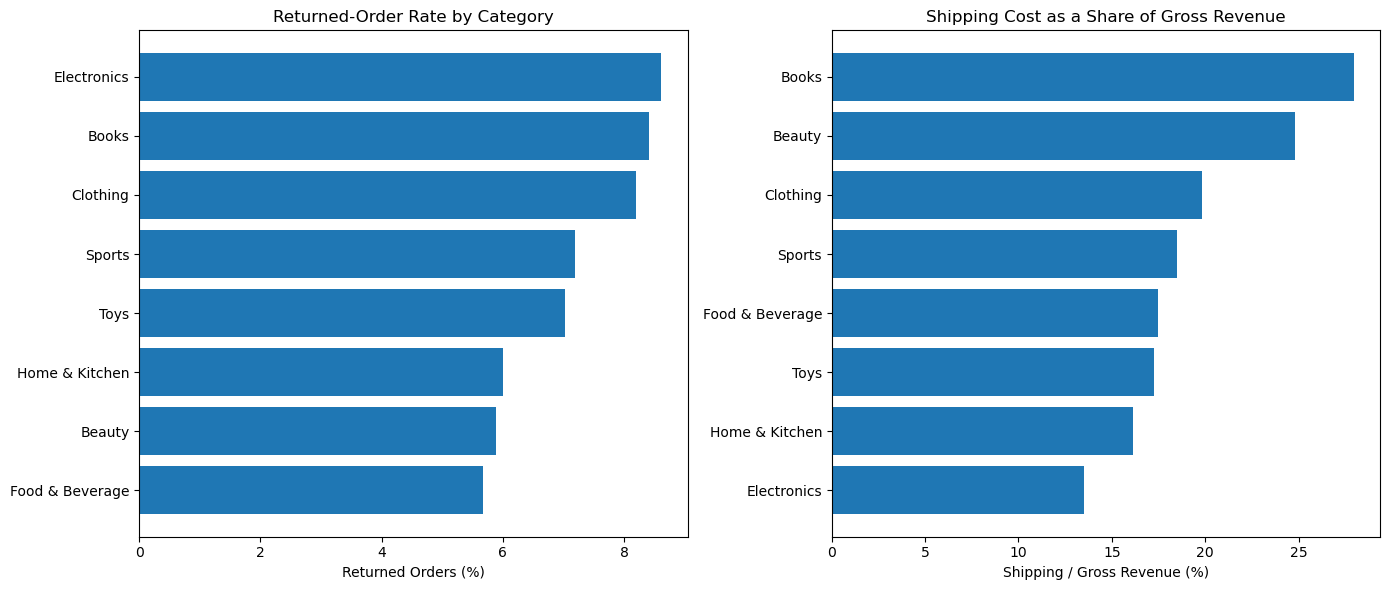

In [20]:

import matplotlib.pyplot as plt

# Sort return rates for a readable horizontal comparison
returns_chart = returns_summary.sort_values(
    "return_rate_pct",
    ascending=True
)

# Sort shipping ratios independently
# because their category rankings may differ
shipping_chart = shipping_summary.sort_values(
    "shipping_to_gross_pct",
    ascending=True
)

# Create two side-by-side visualizations
# for frequency of returns and shipping expense pressure
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Display the percentage of returned orders by category
axes[0].barh(
    returns_chart["primary_category"],
    returns_chart["return_rate_pct"]
)

axes[0].set_title("Returned-Order Rate by Category")
axes[0].set_xlabel("Returned Orders (%)")

# Display shipping cost as a percentage of gross revenue
# to show which categories face the greatest shipping burden
axes[1].barh(
    shipping_chart["primary_category"],
    shipping_chart["shipping_to_gross_pct"]
)

axes[1].set_title("Shipping Cost as a Share of Gross Revenue")
axes[1].set_xlabel("Shipping / Gross Revenue (%)")

# Improve spacing around long category names
plt.tight_layout()

# Show the charts in the final portfolio notebook
plt.show()

# Release the chart after display
plt.close(fig)


In [21]:

# Identify the category with the highest order return rate
highest_return_category = returns_summary.loc[
    returns_summary["return_rate_pct"].idxmax()
]

# Identify the category with the highest
# financial refund burden relative to gross sales
highest_refund_burden = returns_summary.loc[
    returns_summary["refund_to_gross_pct"].idxmax()
]

# Identify the category with the largest
# shipping expense burden relative to gross sales
highest_shipping_burden = shipping_summary.loc[
    shipping_summary["shipping_to_gross_pct"].idxmax()
]

# Require key business findings to match
# our previously reconciled BrightCart analysis
assert highest_return_category["primary_category"] == "Electronics"

assert highest_refund_burden["primary_category"] == (
    "Food & Beverage"
)

assert highest_shipping_burden["primary_category"] == "Books"

# Display validated conclusions for the portfolio
print("BRIGHTCART — OPERATIONAL INSIGHTS")
print("=" * 55)

print(
    "Highest returned-order rate:",
    highest_return_category["primary_category"],
    f"({highest_return_category['return_rate_pct']:.2f}%)"
)

print(
    "Highest refund burden:",
    highest_refund_burden["primary_category"],
    f"({highest_refund_burden['refund_to_gross_pct']:.2f}%)"
)

print(
    "Highest shipping burden:",
    highest_shipping_burden["primary_category"],
    f"({highest_shipping_burden['shipping_to_gross_pct']:.2f}%)"
)

print("\nOperational cost and returns insights validated!")


BRIGHTCART — OPERATIONAL INSIGHTS
Highest returned-order rate: Electronics (8.61%)
Highest refund burden: Food & Beverage (9.50%)
Highest shipping burden: Books (27.96%)

Operational cost and returns insights validated!



## 5. Marketing Performance Analysis

### Business questions

- Which advertising platforms report the strongest attributed ROAS?
- How do spending and cost per conversion differ by platform?
- Which platforms have the greatest historical marketing expenditure?

**Important limitation:** Marketing-attributed revenue does not reconcile with recorded Orders revenue.

Therefore, attributed ROAS is a descriptive marketing metric, not verified incremental return on investment or company profitability.

Conversions are treated as reported conversions, not confirmed new customer acquisitions.


In [22]:

import pandas as pd
from IPython.display import display

# Retrieve the validated marketing records for 2024–2025
# without joining them to the separate Orders dataset
marketing = data["financial_marketing"].copy()

# Group monthly records by advertising platform
# to calculate total marketing spend and reported outcomes
platform_summary = (
    marketing
    .groupby("platform", as_index=False)
    .agg(
        # Calculate historical advertising investment
        spend=("spend", "sum"),

        # Sum reported revenue attributed to each platform
        attributed_revenue=("revenue_attributed", "sum"),

        # Sum advertising clicks across reporting months
        clicks=("clicks", "sum"),

        # Sum recorded conversions without assuming
        # they represent new customer acquisitions
        conversions=("conversions", "sum")
    )
)

# Calculate attributed ROAS using aggregate totals
# rather than averaging individual monthly ROAS values
platform_summary["reported_roas"] = (
    platform_summary["attributed_revenue"]
    / platform_summary["spend"]
)

# Calculate cost per click from total investment and clicks
# to compare reported traffic acquisition costs
platform_summary["cost_per_click"] = (
    platform_summary["spend"]
    / platform_summary["clicks"]
)

# Calculate spend per reported conversion
# without treating it as verified customer acquisition cost
platform_summary["cost_per_conversion"] = (
    platform_summary["spend"]
    / platform_summary["conversions"]
)

# Sort advertising platforms by reported attributed ROAS
# so the highest historical ratio appears first
platform_summary = platform_summary.sort_values(
    "reported_roas",
    ascending=False
).reset_index(drop=True)

# Reconcile spending and attributed revenue totals
# to the marketing dataset used in our previous analysis
assert round(
    platform_summary["spend"].sum() * 100
) == 50350614

assert round(
    platform_summary["attributed_revenue"].sum() * 100
) == 814661520

# Create a separate presentation copy so the
# original financial values remain numeric
platform_display = platform_summary.copy()

# Format monetary measures for readable portfolio tables
for column in [
    "spend",
    "attributed_revenue",
    "cost_per_click",
    "cost_per_conversion"
]:
    platform_display[column] = platform_display[column].map(
        lambda value: f"${value:,.2f}"
    )

# Format ROAS with its multiplier notation
# while retaining numeric values in platform_summary
platform_display["reported_roas"] = (
    platform_display["reported_roas"]
    .map(lambda value: f"{value:.2f}x")
)

# Display the platform performance table
print("BRIGHTCART — MARKETING PERFORMANCE BY PLATFORM")
print("=" * 60)

display(platform_display)

print("\nMarketing spending and attribution totals reconciled!")



BRIGHTCART — MARKETING PERFORMANCE BY PLATFORM


,platform,spend,attributed_revenue,clicks,conversions,reported_roas,cost_per_click,cost_per_conversion
0,TikTok Ads,"$57,229.22","$1,374,627.17",383269,18684,24.02x,$0.15,$3.06
1,Influencer,"$97,663.12","$2,216,974.26",587501,28824,22.70x,$0.17,$3.39
2,Instagram Ads,"$65,154.02","$1,024,639.06",306843,13863,15.73x,$0.21,$4.70
3,Google Ads,"$152,546.48","$2,194,120.83",611740,32309,14.38x,$0.25,$4.72
4,Facebook Ads,"$106,451.93","$1,218,572.43",331746,16968,11.45x,$0.32,$6.27
5,Email Marketing,"$24,461.37","$117,681.45",25971,1370,4.81x,$0.94,$17.86



Marketing spending and attribution totals reconciled!



## 6. Marketing Budget Optimization

### Management objective

Model a 20% reduction in recorded marketing spending.

Two scenarios are evaluated:

1. **Equal allocation:** Distribute the reduction proportionally across platform-month records.
2. **Targeted allocation:** Prioritize platform-month records with lower historical reported ROAS, while limiting each targeted cut to 40% of its original spending.

The model works in whole cents to prevent rounding-related budget violations.

**Scenario limitation:** Historical ROAS is not a forecast of future advertising performance. Reduced spending may also reduce future sales or conversions.


In [23]:

from brightcart.budget_optimizer import optimize_marketing_budget

# Run the independently tested optimization function
# using the marketing records already loaded in this notebook
optimized_budget = optimize_marketing_budget(
    marketing,
    reduction_pct=20,
    maximum_cut_pct=40
)

# Calculate the full original budget in whole cents
# so the financial allocation reconciles exactly
original_cents = int(
    optimized_budget["spend_cents"].sum()
)

# Calculate the reductions proposed by both scenarios
# using their validated whole-cent allocation columns
equal_cents = int(
    optimized_budget["equal_cut_cents"].sum()
)

targeted_cents = int(
    optimized_budget["targeted_cut_cents"].sum()
)

# Calculate the remaining budget after targeted reductions
# without treating it as realized profit improvement
remaining_cents = original_cents - targeted_cents

# Calculate the maximum permitted targeted reduction
# for each record using exact integer arithmetic
maximum_cuts = (
    optimized_budget["spend_cents"] * 40 // 100
)

# Count any targeted allocations exceeding the 40% cap
# rather than comparing rounded displayed percentages
cap_violations = int((
    optimized_budget["targeted_cut_cents"]
    > maximum_cuts
).sum())

# Confirm the standalone optimizer reproduces
# our previously validated BrightCart budget model
assert len(optimized_budget) == 144
assert original_cents == 50350614
assert equal_cents == 10070123
assert targeted_cents == 10070123
assert cap_violations == 0

# Display a clear management comparison
print("BRIGHTCART — MARKETING BUDGET OPTIMIZATION")
print("=" * 60)

print(f"Original budget: ${original_cents / 100:,.2f}")
print(f"Equal reduction: ${equal_cents / 100:,.2f}")
print(f"Targeted reduction: ${targeted_cents / 100:,.2f}")
print(f"Remaining budget: ${remaining_cents / 100:,.2f}")
print("Targeted cap violations:", cap_violations)

print("\nBoth marketing budget scenarios validated!")
print("Savings represent planned expenditure, not net profit.")


BRIGHTCART — MARKETING BUDGET OPTIMIZATION
Original budget: $503,506.14
Equal reduction: $100,701.23
Targeted reduction: $100,701.23
Remaining budget: $402,804.91
Targeted cap violations: 0

Both marketing budget scenarios validated!
Savings represent planned expenditure, not net profit.


In [24]:

# Group the validated budget allocations by platform
# to compare equal and targeted spending reductions
budget_platform_summary = (
    optimized_budget
    .groupby("platform", as_index=False)
    .agg(
        # Sum original marketing spending in whole cents
        original_cents=("spend_cents", "sum"),

        # Sum cuts under the proportional allocation
        equal_cut_cents=("equal_cut_cents", "sum"),

        # Sum cuts under the lower-ROAS-prioritized allocation
        targeted_cut_cents=("targeted_cut_cents", "sum")
    )
)

# Convert whole cents to dollars for business presentation
budget_platform_summary["original_spend"] = (
    budget_platform_summary["original_cents"] / 100
)

budget_platform_summary["equal_cut"] = (
    budget_platform_summary["equal_cut_cents"] / 100
)

budget_platform_summary["targeted_cut"] = (
    budget_platform_summary["targeted_cut_cents"] / 100
)

# Calculate the percentage of each platform's budget
# removed under the targeted scenario
budget_platform_summary["targeted_cut_pct"] = (
    budget_platform_summary["targeted_cut_cents"]
    / budget_platform_summary["original_cents"]
    * 100
)

# Sort platforms by their targeted reduction amount
# so the largest proposed dollar cuts appear first
budget_platform_summary = budget_platform_summary.sort_values(
    "targeted_cut",
    ascending=False
).reset_index(drop=True)

# Create a separate formatted copy for presentation
budget_display = budget_platform_summary[
    [
        "platform",
        "original_spend",
        "equal_cut",
        "targeted_cut",
        "targeted_cut_pct"
    ]
].copy()

# Format the spending and reduction amounts as dollars
for column in ["original_spend", "equal_cut", "targeted_cut"]:
    budget_display[column] = budget_display[column].map(
        lambda value: f"${value:,.2f}"
    )

# Format targeted reduction percentages
budget_display["targeted_cut_pct"] = (
    budget_display["targeted_cut_pct"]
    .map(lambda value: f"{value:.2f}%")
)

# Display the allocation comparison without jinja2
print("BRIGHTCART — BUDGET CUTS BY PLATFORM")
print("=" * 60)

display(budget_display)

print("\nBudget allocation comparison ready!")


BRIGHTCART — BUDGET CUTS BY PLATFORM


,platform,original_spend,equal_cut,targeted_cut,targeted_cut_pct
0,Google Ads,"$152,546.48","$30,509.32","$30,402.55",19.93%
1,Facebook Ads,"$106,451.93","$21,290.40","$29,743.08",27.94%
2,Influencer,"$97,663.12","$19,532.63","$13,157.24",13.47%
3,Instagram Ads,"$65,154.02","$13,030.80","$11,937.07",18.32%
4,Email Marketing,"$24,461.37","$4,892.24","$9,571.55",39.13%
5,TikTok Ads,"$57,229.22","$11,445.84","$5,889.74",10.29%



Budget allocation comparison ready!


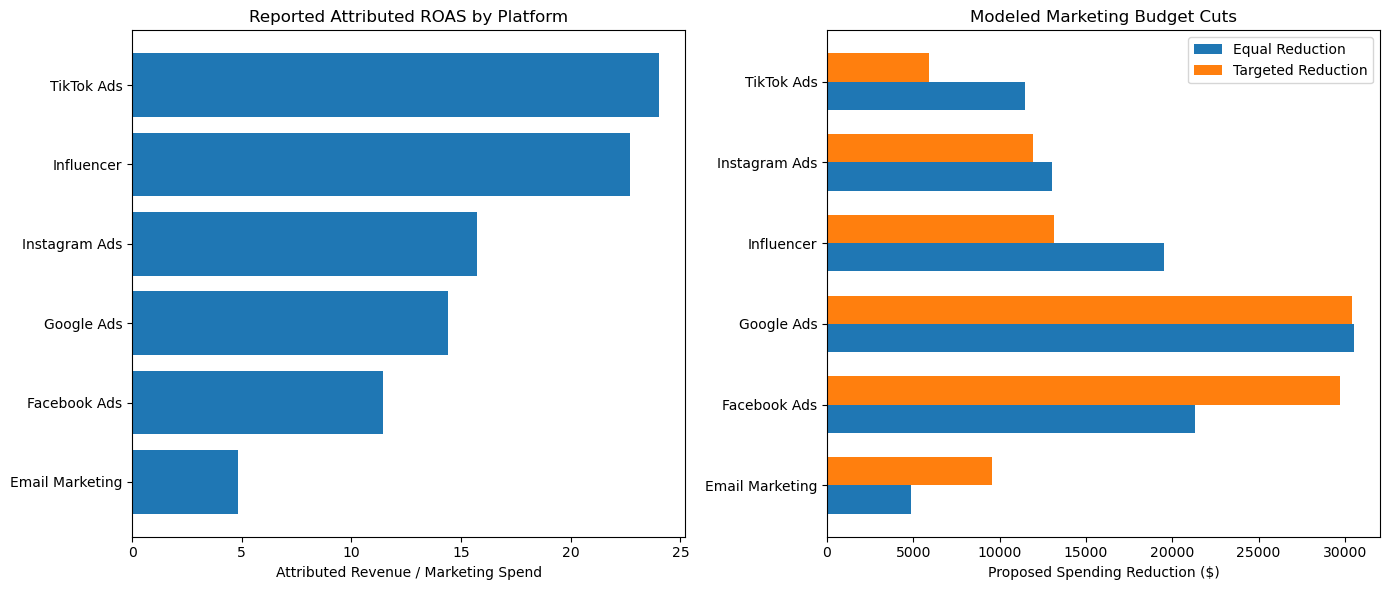

In [25]:

import matplotlib.pyplot as plt
import numpy as np

# Sort platform performance for a readable ROAS comparison
roas_chart = platform_summary.sort_values(
    "reported_roas",
    ascending=True
)

# Sort platform budget allocations for comparison
# using the same platform order in both scenarios
budget_chart = budget_platform_summary.sort_values(
    "platform"
)

# Create a two-panel visualization for the portfolio
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot reported historical attributed ROAS by platform
axes[0].barh(
    roas_chart["platform"],
    roas_chart["reported_roas"]
)

# Label the chart explicitly as attributed performance
axes[0].set_title("Reported Attributed ROAS by Platform")
axes[0].set_xlabel("Attributed Revenue / Marketing Spend")

# Prepare positions for a side-by-side cut comparison
y_positions = np.arange(len(budget_chart))
bar_height = 0.35

# Plot equal reductions for each advertising platform
axes[1].barh(
    y_positions - bar_height / 2,
    budget_chart["equal_cut"],
    height=bar_height,
    label="Equal Reduction"
)

# Plot targeted reductions alongside equal cuts
axes[1].barh(
    y_positions + bar_height / 2,
    budget_chart["targeted_cut"],
    height=bar_height,
    label="Targeted Reduction"
)

# Label the platform positions using actual names
axes[1].set_yticks(y_positions)
axes[1].set_yticklabels(budget_chart["platform"])

# Add the chart title, financial units, and legend
axes[1].set_title("Modeled Marketing Budget Cuts")
axes[1].set_xlabel("Proposed Spending Reduction ($)")
axes[1].legend()

# Improve spacing to keep labels readable
plt.tight_layout()

# Render the two charts inside the final notebook
plt.show()

# Close the figure to prevent duplicate outputs
plt.close(fig)



## 7. Executive Recommendations

### Management decision framework

Three operational improvement opportunities were identified from validated order-level financial records.

1. **Books shipping efficiency:** Investigate packaging, fulfillment methods, and shipping cost relative to basket value.
2. **Marketplace platform fees:** Review selling fees and evaluate lower-cost channel or fulfillment arrangements.
3. **Food & Beverage refunds:** Investigate refund causes, order quality, and fulfillment processes.

A hypothetical 10% improvement is applied to each historical cost or refund base.

These are conditional scenarios, not realized savings or guaranteed increases in profit.

The analysis covers January 2024–December 2025 and does not annualize the projected opportunity.


In [26]:

from brightcart.recommendations import calculate_opportunities
from IPython.display import display

# Calculate the three conditional business improvements
# using the validated 1,997 reporting-period orders
recommendation_summary = calculate_opportunities(
    orders,
    improvement_pct=10
)

# Sum the hypothetical savings across all three recommendations
# without treating the result as realized financial performance
total_hypothetical_savings = (
    recommendation_summary["potential_savings"].sum()
)

# Calculate an illustrative contribution outcome
# assuming all three improvements are achieved
# and all other revenues and expenses remain unchanged
illustrative_contribution = (
    orders["profit"].sum()
    + total_hypothetical_savings
)

# Validate the results against our independent project tests
# using cents to avoid floating-point equality problems
savings_cents = (
    recommendation_summary["potential_savings"] * 100
).round().astype(int)

assert savings_cents.tolist() == [
    62518, 79497, 35046
]

assert savings_cents.sum() == 177061

# Create a display copy while preserving numeric results
# for future scenario calculations
recommendation_display = recommendation_summary.copy()

# Format the historical amounts and modeled savings
# without requiring pandas Styler or jinja2
for column in ["historical_cost", "potential_savings"]:
    recommendation_display[column] = (
        recommendation_display[column]
        .map(lambda amount: f"${amount:,.2f}")
    )

# Format the hypothetical improvement assumption
# as a percentage for management readers
recommendation_display["improvement_pct"] = (
    recommendation_display["improvement_pct"]
    .map(lambda value: f"{value:.0f}%")
)

# Present the finished recommendation table
print("BRIGHTCART — CEO EXECUTIVE RECOMMENDATIONS")
print("=" * 60)

display(recommendation_display)

print(
    f"\nCombined conditional opportunity: "
    f"${total_hypothetical_savings:,.2f}"
)

print(
    f"Illustrative contribution after improvements: "
    f"${illustrative_contribution:,.2f}"
)

print("\nThese are hypothetical scenarios, not realized profit.")


BRIGHTCART — CEO EXECUTIVE RECOMMENDATIONS


,recommendation,historical_cost,improvement_pct,potential_savings
0,Books shipping efficiency,"$6,251.80",10%,$625.18
1,Marketplace fee reduction,"$7,949.69",10%,$794.97
2,Food & Beverage refund reduction,"$3,504.56",10%,$350.46



Combined conditional opportunity: $1,770.61
Illustrative contribution after improvements: $57,990.16

These are hypothetical scenarios, not realized profit.



## 8. Interactive Profitability Dashboard

This dashboard allows users to filter recorded orders by:

- Reporting month.
- Product category.
- Sales channel.

It recalculates net revenue, pre-marketing contribution profit, contribution margin, and returned-order rate.

The accompanying chart compares contribution profit by category or channel.

All metrics use the validated Orders dataset. Marketing attribution is intentionally excluded from the profit calculations.


In [27]:

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Create a separate dashboard dataset from validated orders
# so interactive filtering never modifies our financial source
dashboard_orders = orders.copy()

# Create month labels using the actual transaction dates
# so the dropdown can filter by reporting period
dashboard_orders["report_month"] = (
    dashboard_orders["order_date"].dt.strftime("%Y-%m")
)

# Define one reusable function to calculate and display
# profitability using the selected dashboard filters
def show_final_dashboard(
    month="All",
    category="All",
    channel="All",
    chart_by="Category"
):

    # Start with all validated reporting-period orders
    # whenever the user changes a filter
    filtered = dashboard_orders.copy()

    # Filter to a selected reporting month if requested
    if month != "All":
        filtered = filtered.loc[
            filtered["report_month"] == month
        ]

    # Filter to one category if the selection is not All
    if category != "All":
        filtered = filtered.loc[
            filtered["primary_category"] == category
        ]

    # Filter to one sales channel if requested
    if channel != "All":
        filtered = filtered.loc[
            filtered["channel"] == channel
        ]

    # Handle filter combinations that have no transactions
    # without raising errors or displaying misleading charts
    if filtered.empty:
        print("No orders match the selected filters.")
        return

    # Calculate financial totals from the filtered orders
    # rather than reusing unfiltered summary values
    order_count = filtered["order_id"].nunique()
    net_revenue = filtered["net_revenue"].sum()
    contribution_profit = filtered["profit"].sum()

    # Calculate the revenue-weighted contribution margin
    # and avoid division by zero
    margin_pct = (
        contribution_profit / net_revenue * 100
        if net_revenue != 0
        else float("nan")
    )

    # Count returned orders for the current selection
    # using the original Yes/No return indicator
    returned_count = filtered["returned"].eq("Yes").sum()

    # Calculate returns as a percentage of selected orders
    return_rate_pct = returned_count / order_count * 100

    # Display key business metrics before drawing charts
    print("BRIGHTCART — FINAL INTERACTIVE DASHBOARD")
    print("=" * 60)

    print(f"Orders: {order_count:,}")
    print(f"Net revenue: ${net_revenue:,.2f}")
    print(
        f"Pre-marketing contribution: "
        f"${contribution_profit:,.2f}"
    )
    print(f"Contribution margin: {margin_pct:.2f}%")
    print(f"Returned-order rate: {return_rate_pct:.2f}%")

    # Choose the requested grouping dimension
    # to switch between category and channel analysis
    grouping_column = (
        "primary_category"
        if chart_by == "Category"
        else "channel"
    )

    # Calculate contribution profit by the selected dimension
    # using only transactions matching the current filters
    chart_summary = (
        filtered
        .groupby(grouping_column, as_index=False)
        .agg(
            contribution_profit=("profit", "sum")
        )
        .sort_values("contribution_profit", ascending=True)
    )

    # Create a horizontal chart with readable category names
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.barh(
        chart_summary[grouping_column],
        chart_summary["contribution_profit"]
    )

    # Add financial metric labels for portfolio clarity
    ax.set_title(
        f"Pre-Marketing Contribution by {chart_by}"
    )
    ax.set_xlabel("Contribution Profit ($)")

    # Add a zero reference for possible negative values
    ax.axvline(0, linewidth=1)

    # Display the completed visualization
    plt.tight_layout()
    plt.show()
    plt.close(fig)


BRIGHTCART — FINAL INTERACTIVE DASHBOARD
Orders: 1,997
Net revenue: $236,015.05
Pre-marketing contribution: $56,219.55
Contribution margin: 23.82%
Returned-order rate: 7.21%


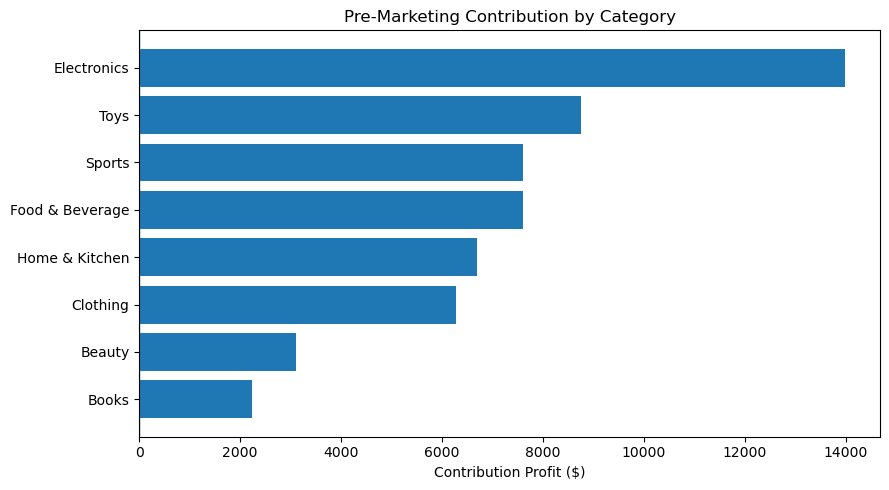

BRIGHTCART — FINAL INTERACTIVE DASHBOARD
Orders: 238
Net revenue: $18,804.97
Pre-marketing contribution: $2,236.04
Contribution margin: 11.89%
Returned-order rate: 8.40%


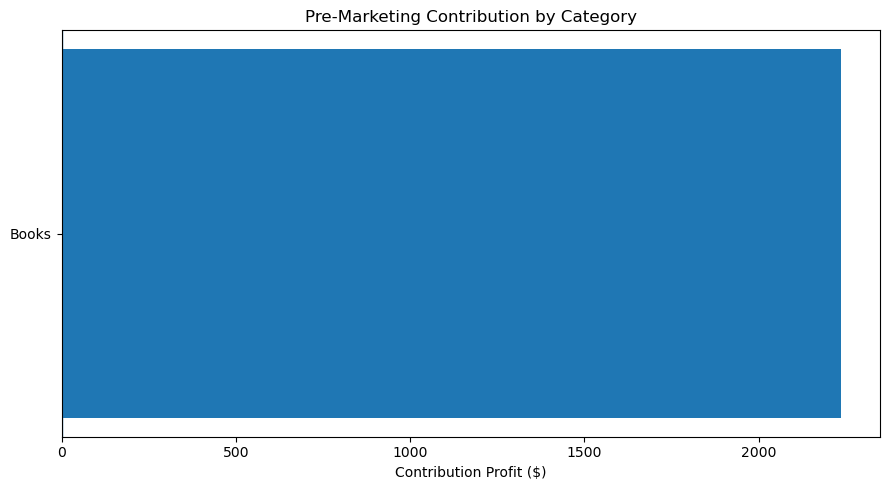

In [28]:

# Test the complete reporting-period financial baseline
# using all months, categories, and channels
show_final_dashboard(
    month="All",
    category="All",
    channel="All",
    chart_by="Category"
)

# Test category filtering with the previously
# validated Books profitability figures
show_final_dashboard(
    month="All",
    category="Books",
    channel="All",
    chart_by="Category"
)


In [32]:
import ipywidgets as widgets
from IPython.display import display

In [33]:

import ipywidgets as widgets
from IPython.display import display

# Build the available reporting-month options directly
# from the validated Orders dates
month_options = sorted(
    dashboard_orders["report_month"].unique()
)

# Build the product-category options from actual data
# rather than manually listing category names
category_options = sorted(
    dashboard_orders["primary_category"].unique()
)

# Build the sales-channel options from actual data
# so future datasets can introduce new channels
channel_options = sorted(
    dashboard_orders["channel"].unique()
)

# Create the reporting-month dropdown control
month_filter = widgets.Dropdown(
    options=["All"] + list(month_options),
    value="All",
    description="Month:"
)

# Create the category dropdown for product analysis
category_filter = widgets.Dropdown(
    options=["All"] + list(category_options),
    value="All",
    description="Category:"
)

# Create the sales-channel dropdown
channel_filter = widgets.Dropdown(
    options=["All"] + list(channel_options),
    value="All",
    description="Channel:"
)

# Create a control for switching the chart breakdown
chart_filter = widgets.Dropdown(
    options=["Category", "Channel"],
    value="Category",
    description="Chart by:"
)

# Connect the dropdowns to the validated dashboard function
# so KPI calculations update when users change selections
interactive_results = widgets.interactive_output(
    show_final_dashboard,
    {
        "month": month_filter,
        "category": category_filter,
        "channel": channel_filter,
        "chart_by": chart_filter
    }
)

# Arrange the dashboard filters in two horizontal rows
# to make the notebook easy for a reviewer to explore
controls = widgets.VBox([
    widgets.HBox([month_filter, category_filter]),
    widgets.HBox([channel_filter, chart_filter])
])

# Display the interactive controls and their results
display(controls, interactive_results)


Output()


## 9. Final Conclusions and Management Priorities

### Financial performance

Across 1,997 orders in the shared reporting period, BrightCart generated:

- **Net revenue:** $236,015.05
- **Pre-marketing  transaction  contribution:** $56,219.55
- **Contribution margin:** 23.82%
- **Returned-order rate:** 7.21%

All recorded order financial equations were successfully reconciled.

### Key business findings

**Product profitability:** Electronics generated the highest contribution profit at $13,973.46. Books had the lowest contribution margin at 11.89%.

**Sales channels:** Website generated the greatest total channel contribution at $25,034.31, while Mobile App achieved the highest contribution margin at 29.74%. Marketplace had the lowest margin at 13.03%.

**Operational risks:** Electronics recorded the highest returned-order rate at 8.61%. Food & Beverage had the highest refund-to-gross-revenue ratio at 9.50%. Books had the highest shipping-to-gross-revenue ratio at 27.96%.

**Marketing:** Historical marketing spending totaled $503,506.14. A modeled 20% reduction produced a proposed spending decrease of $100,701.23 under both allocation scenarios, subject to the targeted scenario's per-record cut cap.

### Recommended management actions

1. Investigate ways to improve Books shipping efficiency.
2. Review Marketplace fees and channel economics.
3. Investigate the causes of Food & Beverage refunds.

A hypothetical 10% improvement in these three cost or refund bases represents a combined conditional opportunity of **$1,770.61** across the historical reporting period.

### Analytical limitations

- Transaction contribution excludes marketing expenditure and other business expenses not represented in the Orders data.
- Marketing-attributed revenue does not reconcile with recorded Orders revenue.
- The available datasets do not support reliable product-to-order joins.
- Historical marketing ROAS does not establish causality or predict future results.
- Modeled spending reductions and operational improvements are scenarios, not guaranteed financial outcomes.

### Final takeaway

BrightCart demonstrates how validated financial analysis, operational diagnostics, scenario modeling, and interactive dashboards can support more transparent e-commerce management decisions.

The strongest next steps are to investigate high-burden operational costs, test improvement initiatives, and improve the consistency of marketing and transaction-level reporting.
